In [2]:
# pip install langgraph

In [4]:
from typing import TypedDict

# lets define our state ( working memory)
class SimpleState(TypedDict):
    input_text : str
    output_text : str


In [9]:
def process_input(state: SimpleState) -> SimpleState:
    # Here you can process the input_text and generate output_text
    state['output_text'] = state['input_text'].upper()  # Example processing
    return state


def add_prefix(state: SimpleState) -> SimpleState:
    state["input_text"] = "Naukari: " + state["output_text"]
    return state




In [10]:
from langgraph.graph import StateGraph, START, END


builder = StateGraph(SimpleState)

# Define the node
builder.add_node("process_input", process_input)
builder.add_node("add_prefix", add_prefix)

# I will combine them using edges
builder.add_edge(START, "process_input")
builder.add_edge("process_input", "add_prefix")
builder.add_edge("add_prefix", END)

graph = builder.compile()


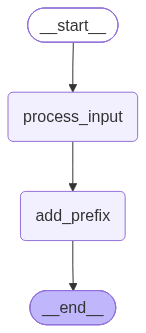

In [11]:
graph

In [12]:
initial_state = {
    "input_text": "Hello, how can I help you?",
    "output_text": ""
}


graph.invoke(initial_state)


{'input_text': 'Naukari: HELLO, HOW CAN I HELP YOU?',
 'output_text': 'HELLO, HOW CAN I HELP YOU?'}